# 08 — Modelo a fondo: regresión logística

**Objetivo:** entender la regresión logística lo suficiente como para
explicarla y defender cada parámetro. Al terminar deberías poder explicar:
- cómo convierte las features en una probabilidad (puntaje lineal + sigmoide);
- qué es la **frontera de decisión**;
- cómo "aprende" (minimizar la pérdida logarítmica);
- qué es la **regularización** y el parámetro **C**, y por qué importa tanto
  con 105 features y 50 grabaciones;
- qué hace `class_weight="balanced"`;
- cómo leer los **coeficientes** (y sus límites).

¿Por qué empezar por este modelo? Es el más simple de la tesis, fue el mejor
en pulmonares y es el mismo que se usa en epidemiología: si alguna vez leíste
un *odds ratio* ajustado, viste una regresión logística.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.paths import OUT_DIR

NO_FEATURES = ["file_id", "label", "label_binary"]


def cargar(subset):
    df = pd.read_csv(OUT_DIR / f"{subset.lower()}_features.csv")
    return df.drop(columns=NO_FEATURES), df["label_binary"].values


X_ls, y_ls = cargar("LS")
X_hs, y_hs = cargar("HS")

## 1. De un puntaje a una probabilidad

La regresión logística hace dos pasos:

**Paso 1: un puntaje lineal.** Multiplica cada feature por un **peso**
(coeficiente) y suma todo, más una constante (el *intercepto*):

$$z = b_0 + w_1 x_1 + w_2 x_2 + \dots + w_{105} x_{105}$$

Es la misma idea que un score clínico de riesgo: cada factor suma o resta
puntos según su peso. Un peso positivo empuja hacia "patológico"; uno
negativo, hacia "normal".

**Paso 2: la sigmoide.** El puntaje z puede ser cualquier número (−50, 3,
120...). Para convertirlo en una probabilidad entre 0 y 1 se usa la función
**sigmoide**:

$$p = \frac{1}{1 + e^{-z}}$$

- si z es muy negativo, p ≈ 0 (casi seguro normal);
- si z = 0, p = 0,5 (indeciso);
- si z es muy positivo, p ≈ 1 (casi seguro patológico).

(Para quien viene de epidemiología: z es el logaritmo de los *odds* de ser
patológico. Por eso, como vamos a ver, cada peso se traduce en un *odds ratio*.)

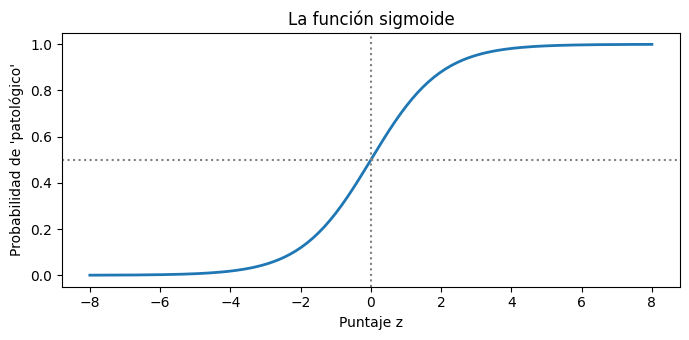

In [2]:
z = np.linspace(-8, 8, 200)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(z, 1 / (1 + np.exp(-z)), lw=2)
ax.axhline(0.5, color="gray", ls=":")
ax.axvline(0, color="gray", ls=":")
ax.set(xlabel="Puntaje z", ylabel="Probabilidad de 'patológico'", title="La función sigmoide")
fig.tight_layout()

## 2. Con una sola feature

Empezamos con la feature que mejor separa las clases en pulmonares cuando se
usa sola. La estandarizamos (media 0, desvío 1) y entrenamos una regresión
logística solo con ella.

*(Elegir la feature mirando todos los datos está bien para **entender** el
modelo; para **evaluarlo** no, por la fuga de información de la notebook 03.)*

Feature: mfcc_delta_10_std
Intercepto b0 = 1.97, peso w1 = 2.02
El modelo dice 'patológico' cuando z > 0, o sea cuando la feature > -0.98 desvíos


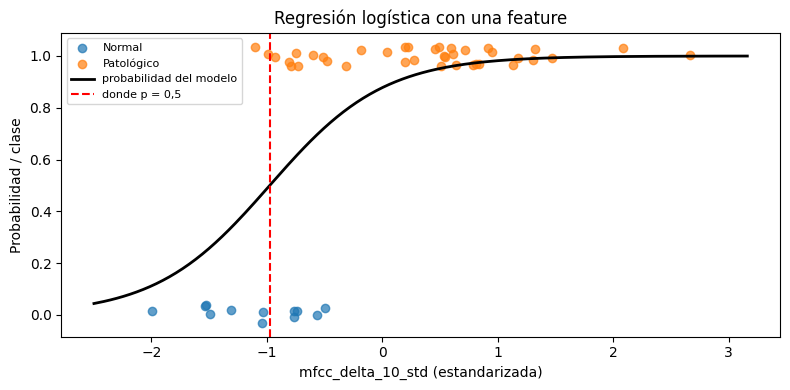

In [3]:
auc_individual = X_ls.apply(lambda col: roc_auc_score(y_ls, col))
FEATURE = (auc_individual - 0.5).abs().idxmax()
x = StandardScaler().fit_transform(X_ls[[FEATURE]])
m1 = LogisticRegression().fit(x, y_ls)
b0, w1 = m1.intercept_[0], m1.coef_[0, 0]
print(f"Feature: {FEATURE}")
print(f"Intercepto b0 = {b0:.2f}, peso w1 = {w1:.2f}")
print(f"El modelo dice 'patológico' cuando z > 0, o sea cuando la feature > {-b0 / w1:.2f} desvíos")

grilla = np.linspace(x.min() - 0.5, x.max() + 0.5, 200)
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(x[y_ls == 0, 0], np.zeros((y_ls == 0).sum()) + np.random.uniform(-0.04, 0.04, (y_ls == 0).sum()),
           label="Normal", alpha=0.7)
ax.scatter(x[y_ls == 1, 0], np.ones((y_ls == 1).sum()) + np.random.uniform(-0.04, 0.04, (y_ls == 1).sum()),
           label="Patológico", alpha=0.7)
ax.plot(grilla, m1.predict_proba(grilla.reshape(-1, 1))[:, 1], color="black", lw=2, label="probabilidad del modelo")
ax.axvline(-b0 / w1, color="red", ls="--", label="donde p = 0,5")
ax.set(xlabel=f"{FEATURE} (estandarizada)", ylabel="Probabilidad / clase",
       title="Regresión logística con una feature")
ax.legend(fontsize=8)
fig.tight_layout()

La curva negra es la sigmoide "acomodada" a los datos: el modelo eligió el
peso y el intercepto que mejor separan los puntos azules de los naranjas. El
peso dice qué tan **empinada** es la curva (qué tan rápido cambia la
probabilidad con la feature) y su signo, **hacia qué lado** sube.

## 3. Con dos features: la frontera de decisión

Con dos features, el modelo dice "patológico" cuando
b0 + w1·x1 + w2·x2 > 0. El borde, donde el puntaje es exactamente 0 (p = 0,5),
es una **línea recta**: la **frontera de decisión**. Con 105 features es lo
mismo, pero la "línea" es un plano en 105 dimensiones. Por eso se dice que la
regresión logística es un modelo **lineal**: separa las clases con un corte recto.

z = 2.24 + 1.59·mfcc_delta_10_std + 1.46·mfcc_6_mean


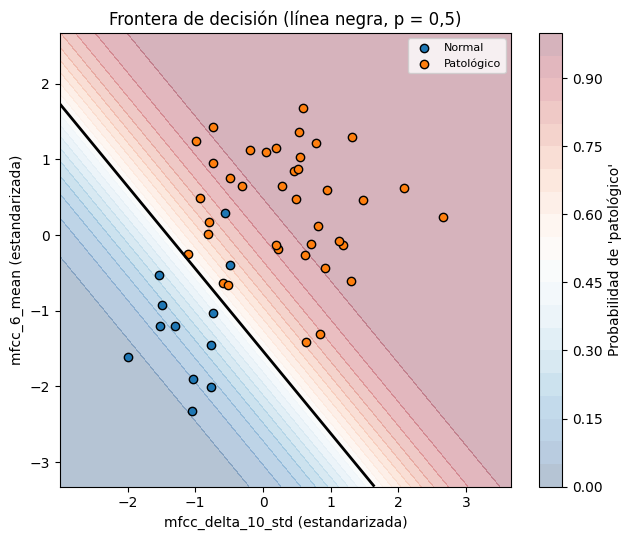

In [4]:
DOS = list((auc_individual - 0.5).abs().sort_values(ascending=False).index[:2])
x2 = StandardScaler().fit_transform(X_ls[DOS])
m2 = LogisticRegression().fit(x2, y_ls)
b0, (w1, w2) = m2.intercept_[0], m2.coef_[0]

fig, ax = plt.subplots(figsize=(6.5, 5.5))
xx, yy = np.meshgrid(np.linspace(x2[:, 0].min() - 1, x2[:, 0].max() + 1, 200),
                     np.linspace(x2[:, 1].min() - 1, x2[:, 1].max() + 1, 200))
pp = m2.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)
fondo = ax.contourf(xx, yy, pp, levels=20, cmap="RdBu_r", alpha=0.3)
ax.contour(xx, yy, pp, levels=[0.5], colors="black", linewidths=2)
for clase, color, nombre in [(0, "tab:blue", "Normal"), (1, "tab:orange", "Patológico")]:
    ax.scatter(x2[y_ls == clase, 0], x2[y_ls == clase, 1], c=color, edgecolor="k", label=nombre)
fig.colorbar(fondo, ax=ax, label="Probabilidad de 'patológico'")
ax.set(xlabel=f"{DOS[0]} (estandarizada)", ylabel=f"{DOS[1]} (estandarizada)",
       title="Frontera de decisión (línea negra, p = 0,5)")
ax.legend(fontsize=8)
fig.tight_layout()
print(f"z = {b0:.2f} + {w1:.2f}·{DOS[0]} + {w2:.2f}·{DOS[1]}")

## 4. Cómo aprende: la pérdida logarítmica

"Entrenar" es elegir los pesos. ¿Con qué criterio? Para cada grabación, el
modelo recibe una **penalización** según la probabilidad que le dio a su
clase verdadera: si le dio una probabilidad alta, poca penalización; si le dio
una probabilidad baja (estaba seguro y se equivocó), mucha:

$$\text{penalización} = -\log(\text{probabilidad asignada a la clase correcta})$$

El algoritmo prueba pesos, mide la penalización total sobre las grabaciones
de entrenamiento y los va ajustando, paso a paso, hasta que no puede bajarla
más. En scikit-learn ese algoritmo se llama `lbfgs`, y `max_iter` es la
cantidad máxima de pasos permitidos. La tesis usa `max_iter=2000` solo para
asegurarse de que llegue al final (con el valor por defecto, 100, a veces
avisa que no terminó de ajustar).

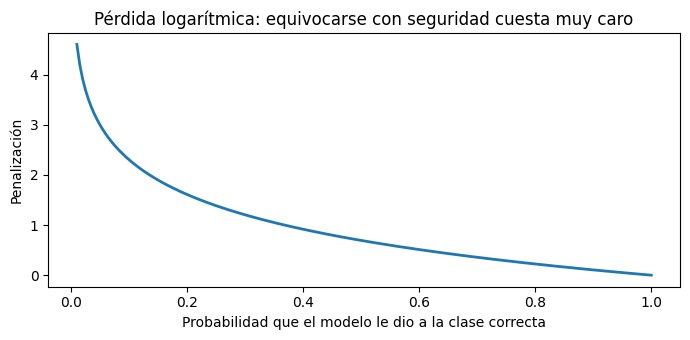

In [5]:
p = np.linspace(0.01, 1, 200)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(p, -np.log(p), lw=2)
ax.set(xlabel="Probabilidad que el modelo le dio a la clase correcta", ylabel="Penalización",
       title="Pérdida logarítmica: equivocarse con seguridad cuesta muy caro")
fig.tight_layout()

## 5. Con las 105 features, y por qué estandarizar

El modelo de la tesis usa las 105 features: 105 pesos y un intercepto. Antes
se **estandarizan** (el `StandardScaler` del pipeline) por dos razones:
- para que los pesos sean **comparables**: cada peso mide el efecto de subir
  **un desvío estándar** esa feature, sin importar si se mide en Hz o en milésimas;
- para que la regularización (sección siguiente) trate a todas las features
  por igual.

## 6. La regularización y el parámetro C

Con 105 features y 50 grabaciones, el modelo **siempre** puede encontrar pesos
que separen perfecto las grabaciones de entrenamiento (vimos en la notebook
07 que el AUC de entrenamiento da 1,0). Para lograrlo, los pesos crecen y
crecen, y el modelo termina "memorizando" ruido.

La **regularización** agrega a la penalización un costo por tener pesos
grandes (en la versión por defecto, la "L2", el costo es la suma de los pesos
al cuadrado). El modelo tiene que equilibrar dos cosas: ajustarse a los datos
y mantener los pesos chicos. Es una forma de decirle "no te creas demasiado
cada detalle de estas 50 grabaciones".

El parámetro **C** controla ese equilibrio, al revés de lo que uno esperaría:
- **C chico** = regularización **fuerte** = pesos chicos = modelo más "prudente";
- **C grande** = regularización **débil** = pesos grandes = modelo más
  "flexible" (y más propenso a sobreajustar).

La tesis usa el valor por defecto, **C = 1**. Veamos qué pasa al cambiarlo:

subconjunto         C  AUC (validación)  tamaño total de los pesos
         LS     0.001             0.980                      0.630
         LS     0.010             0.992                      2.943
         LS     0.100             0.995                      7.396
         LS     1.000             0.998                     13.741
         LS    10.000             0.998                     21.263
         LS   100.000             0.999                     29.816
         LS 10000.000             0.999                     48.243
         HS     0.001             0.746                      0.497
         HS     0.010             0.744                      2.450
         HS     0.100             0.730                      7.833
         HS     1.000             0.696                     19.195
         HS    10.000             0.671                     36.203
         HS   100.000             0.655                     56.012
         HS 10000.000             0.627                     95

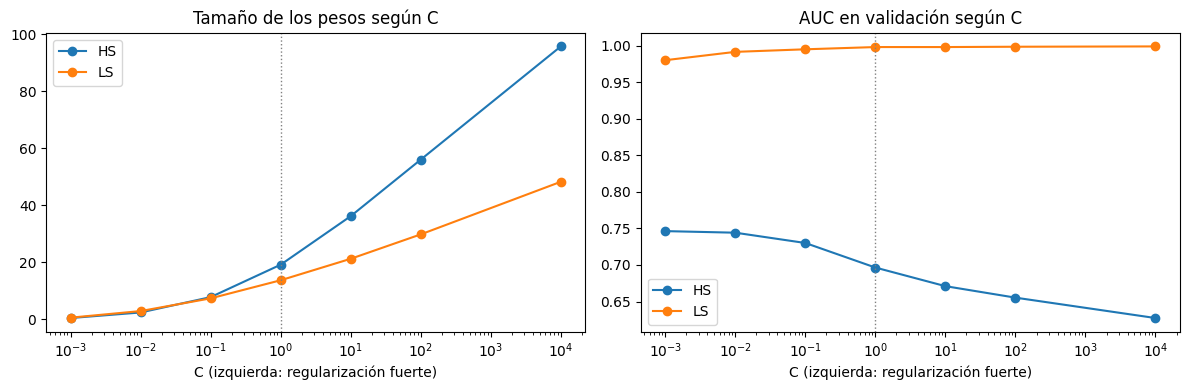

In [6]:
VALORES_C = [0.001, 0.01, 0.1, 1, 10, 100, 10000]


def auc_cv(X, y, C, repeticiones=5):
    modelo = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000, class_weight="balanced"))
    return np.mean([roc_auc_score(y, cross_val_predict(modelo, X, y, method="predict_proba",
                                                       cv=StratifiedKFold(5, shuffle=True, random_state=s))[:, 1])
                    for s in range(repeticiones)])


filas = []
for subset, (X, y) in {"LS": (X_ls, y_ls), "HS": (X_hs, y_hs)}.items():
    for C in VALORES_C:
        pesos = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000, class_weight="balanced")
                              ).fit(X, y)[-1].coef_[0]
        filas.append({"subconjunto": subset, "C": C, "AUC (validación)": auc_cv(X, y, C),
                      "tamaño total de los pesos": np.abs(pesos).sum()})
reg = pd.DataFrame(filas)
print(reg.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for subset, d in reg.groupby("subconjunto"):
    axes[0].plot(d["C"], d["tamaño total de los pesos"], "o-", label=subset)
    axes[1].plot(d["C"], d["AUC (validación)"], "o-", label=subset)
for ax, titulo in zip(axes, ["Tamaño de los pesos según C", "AUC en validación según C"]):
    ax.set(xscale="log", xlabel="C (izquierda: regularización fuerte)", title=titulo)
    ax.axvline(1, color="gray", ls=":", lw=1)
    ax.legend()
fig.tight_layout()

**Cómo leerlo:**
- A la izquierda: cuanto más grande es C (menos regularización), más grandes
  los pesos.
- A la derecha: en **pulmonares** casi no importa, la señal es tan clara que
  cualquier C funciona. En **cardíacos**, el AUC **mejora al regularizar más**
  (C chico) y empeora al regularizar menos.

Es el compromiso entre **sesgo y varianza** de tu marco teórico (sección 2.8):
con pocas muestras y muchas features, lo que más daño hace es la **varianza**
(el modelo se adapta demasiado a la muestra particular). Regularizar aumenta
un poco el sesgo pero baja mucho la varianza. Con una señal débil, como la
cardíaca, eso se nota.

**Cuidado:** esto **no** autoriza a elegir el C que mejor dio en este gráfico
y reportar ese AUC: sería elegir un hiperparámetro mirando los resultados
(notebook 07, sección 6). Si se quiere usar otro C, hay dos caminos honestos:
fijarlo de antemano con un argumento (por ejemplo, "regularización fuerte
porque p ≫ n") o elegirlo con validación cruzada anidada.

## 7. `class_weight="balanced"`

Le dice al modelo que equivocarse con una grabación de la clase chica cuesta
más. Cada clase recibe un peso igual a
total / (2 × cantidad de esa clase):

In [7]:
for subset, y in [("LS", y_ls), ("HS", y_hs)]:
    n, n0, n1 = len(y), (y == 0).sum(), (y == 1).sum()
    print(f"{subset}: peso de cada normal = {n / (2 * n0):.2f}, peso de cada patológico = {n / (2 * n1):.2f}")

LS: peso de cada normal = 2.08, peso de cada patológico = 0.66
HS: peso de cada normal = 2.78, peso de cada patológico = 0.61


En pulmonares, equivocarse con un normal "cuesta" ~3 veces más que con un
patológico. Así, en total, las dos clases pesan lo mismo en el entrenamiento,
sin inventar datos (a diferencia de SMOTE).

## 8. Leer los coeficientes

Entrenamos el modelo de la tesis (105 features, C = 1, `class_weight`) con
**todas** las grabaciones pulmonares, solo para mirar sus pesos. *(Para
evaluarlo se usa validación cruzada; para interpretarlo, se mira el modelo
entrenado con todo.)*

                          peso  odds ratio por 1 desvío
spectral_contrast_5_std  -0.41                     0.67
mfcc_6_mean               0.38                     1.46
mfcc_5_mean               0.35                     1.42
mfcc_7_mean               0.33                     1.38
zcr_mean                 -0.32                     0.73
spectral_contrast_4_mean -0.31                     0.73
mfcc_delta_10_std         0.31                     1.36
mfcc_delta_13_std         0.28                     1.33
spectral_contrast_7_mean -0.27                     0.76
spectral_centroid_mean   -0.26                     0.77
mfcc_6_std               -0.25                     0.78
mfcc_4_std               -0.25                     0.78


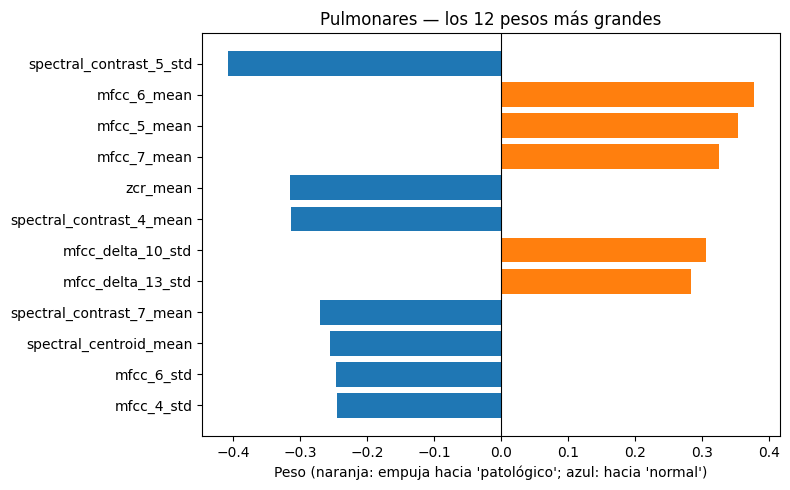

In [8]:
def pesos_modelo(X, y):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, class_weight="balanced")).fit(X, y)
    return pd.Series(m[-1].coef_[0], index=X.columns)


pesos_ls = pesos_modelo(X_ls, y_ls)
top = pesos_ls.reindex(pesos_ls.abs().sort_values(ascending=False).index).head(12)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index[::-1], top.values[::-1], color=["tab:orange" if v > 0 else "tab:blue" for v in top.values[::-1]])
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Peso (naranja: empuja hacia 'patológico'; azul: hacia 'normal')",
       title="Pulmonares — los 12 pesos más grandes")
fig.tight_layout()

print(pd.DataFrame({"peso": top, "odds ratio por 1 desvío": np.exp(top)}).round(2).to_string())

**Cómo se lee un peso.** Como las features están estandarizadas, el peso es
el cambio en el logaritmo de los *odds* de "patológico" por cada **desvío
estándar** que sube esa feature, manteniendo las demás fijas. Su exponencial
es el **odds ratio**: un peso de −0,4 equivale a un OR de ~0,67 por desvío
(los *odds* de patológico bajan un tercio).

**Pero hay que leerlos con cuidado:**
1. **Features correlacionadas se reparten el peso.** Si dos features miden
   casi lo mismo (por ejemplo, varios MFCC vecinos), el modelo puede darle
   peso a una, a la otra o repartirlo. El peso de una feature sola no es "su
   importancia".
2. **La regularización achica todos los pesos**, así que su tamaño absoluto
   depende de C. Lo que importa es el orden y el signo.
3. **Asociación, no causa:** un peso dice qué features usa el modelo para
   decidir, no qué produce la patología.

¿Son estables? Repetimos el ajuste con 200 remuestreos bootstrap y contamos
en qué fracción cada peso del top mantiene su signo:

In [9]:
rng = np.random.default_rng(0)
signos = []
while len(signos) < 200:
    i = rng.integers(0, len(y_ls), len(y_ls))
    if len(np.unique(y_ls[i])) == 2:
        signos.append(np.sign(pesos_modelo(X_ls.iloc[i], y_ls[i])))
estabilidad = (pd.DataFrame(signos) == np.sign(pesos_ls)).mean()
print("Fracción de remuestreos en que cada peso del top mantiene su signo:")
print(estabilidad[top.index].round(2).to_string())

Fracción de remuestreos en que cada peso del top mantiene su signo:
spectral_contrast_5_std     1.0
mfcc_6_mean                 1.0
mfcc_5_mean                 1.0
mfcc_7_mean                 1.0
zcr_mean                    1.0
spectral_contrast_4_mean    1.0
mfcc_delta_10_std           1.0
mfcc_delta_13_std           1.0
spectral_contrast_7_mean    1.0
spectral_centroid_mean      1.0
mfcc_6_std                  1.0
mfcc_4_std                  1.0


Los pesos más grandes mantienen su signo en (casi) todos los remuestreos: la
**dirección** del efecto es estable, aunque el tamaño exacto varíe.

Un aviso para **cardíacos**: entre sus pesos más grandes aparecen varios
máximos y mínimos de MFCC (`mfcc_*_max`, `mfcc_*_min`), que en la notebook 03
vimos que a menudo vienen de las tramas del borde, que son relleno
artificial. Conviene interpretarlos con cuidado hasta corregir la extracción.

In [10]:
pesos_hs = pesos_modelo(X_hs, y_hs)
print("Cardíacos — los 8 pesos más grandes:")
print(pesos_hs.reindex(pesos_hs.abs().sort_values(ascending=False).index).head(8).round(2).to_string())

Cardíacos — los 8 pesos más grandes:
mfcc_5_max                 -0.72
spectral_contrast_3_std    -0.71
mfcc_4_max                 -0.66
mfcc_9_min                  0.60
mfcc_11_max                 0.60
spectral_contrast_4_mean    0.50
mfcc_4_std                 -0.49
mfcc_delta_4_std           -0.46


## 9. Los hiperparámetros de la tesis (Tabla 7.1), uno por uno

| Parámetro | Valor | Qué hace | Cómo justificarlo |
|---|---|---|---|
| `penalty` | `"l2"` (por defecto) | tipo de regularización: castiga la suma de los pesos al cuadrado | estándar; achica todos los pesos sin anular ninguno |
| `C` | 1 (por defecto) | inverso de la fuerza de la regularización | valor por defecto, fijado de antemano para no elegirlo mirando los resultados |
| `solver` | `"lbfgs"` (por defecto) | algoritmo que busca los pesos | estándar para este tamaño de datos |
| `max_iter` | 2000 | máximo de pasos del algoritmo | asegura que termine de ajustar; no cambia el modelo si ya convergía |
| `class_weight` | `"balanced"` o ninguno (con SMOTE) | peso de cada clase en la penalización | compensa el desbalance sin inventar datos |

Una propuesta para discutir con tu directora: dado que con p ≫ n la teoría
anticipa que la varianza domina, se podría fijar **de antemano** una
regularización más fuerte (por ejemplo C = 0,1) con ese argumento teórico, o
elegir C con validación anidada. Lo que no conviene es elegirlo mirando el
gráfico de la sección 6.

## 10. Cómo explicárselo a tu directora (en 5 frases)

1. *"La regresión logística calcula un puntaje sumando las 105 features
   estandarizadas, cada una multiplicada por un peso, y lo convierte en una
   probabilidad de patológico con la función sigmoide."*
2. *"Los pesos se eligen minimizando la pérdida logarítmica: el modelo se
   penaliza más cuanto más seguro está de una respuesta equivocada."*
3. *"Como tenemos más features que grabaciones, uso regularización L2, que
   castiga los pesos grandes para que el modelo no memorice ruido; C controla
   cuánto, y uso el valor por defecto fijado de antemano."*
4. *"Separa las clases con una frontera lineal; en pulmonares eso alcanza
   (AUC ~0,99 por grabación), en cardíacos no (~0,70), y ahí regularizar más
   ayuda, como predice el compromiso sesgo-varianza."*
5. *"Es interpretable: cada peso es un log-odds ratio por desvío estándar de
   la feature, aunque con features correlacionadas hay que leerlos con
   cuidado."*

## 11. Tu turno

Cambiá `C` y mirá cómo cambia la frontera con dos features. ¿Qué pasa con
C = 0,01? ¿Y con C = 1000?

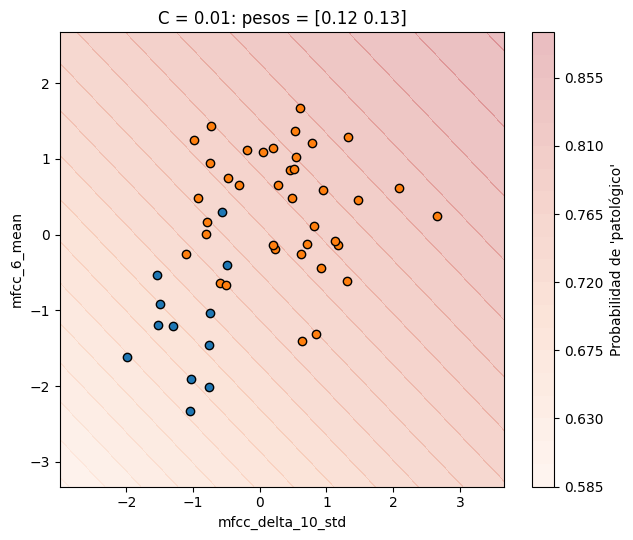

In [11]:
C_ELEGIDO = 0.01

m2c = LogisticRegression(C=C_ELEGIDO).fit(x2, y_ls)
pp = m2c.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
fondo = ax.contourf(xx, yy, pp, levels=20, cmap="RdBu_r", alpha=0.3, vmin=0, vmax=1)
ax.contour(xx, yy, pp, levels=[0.5], colors="black", linewidths=2)
for clase, color in [(0, "tab:blue"), (1, "tab:orange")]:
    ax.scatter(x2[y_ls == clase, 0], x2[y_ls == clase, 1], c=color, edgecolor="k")
fig.colorbar(fondo, ax=ax, label="Probabilidad de 'patológico'")
ax.set(xlabel=DOS[0], ylabel=DOS[1], title=f"C = {C_ELEGIDO}: pesos = {np.round(m2c.coef_[0], 2)}")
fig.tight_layout()

Con C chico, las probabilidades quedan cerca de 0,5 en todos lados (el modelo
es "prudente": colores pálidos). Con C grande, pasa de 0 a 1 de golpe cerca de
la frontera (el modelo está "muy seguro").

## Preguntas de control

1. ¿Cuáles son los dos pasos con los que la regresión logística convierte las
   features en una probabilidad?
2. ¿Qué es la frontera de decisión y por qué se dice que el modelo es lineal?
3. ¿Qué penaliza la pérdida logarítmica? ¿Para qué sirve `max_iter`?
4. ¿Por qué se estandarizan las features antes?
5. ¿Qué es la regularización y qué controla C? ¿C chico es más o menos regularización?
6. ¿Por qué en cardíacos el AUC mejora al regularizar más? Relacionalo con
   sesgo y varianza. ¿Por qué no podemos elegir C mirando ese gráfico?
7. ¿Qué hace `class_weight="balanced"`? ¿En qué se diferencia de SMOTE?
8. ¿Cómo se interpreta un peso de −0,4? ¿Por qué no es la "importancia" de la feature?

## Respuestas a las preguntas de control

*(Intentá responder antes de leer.)*

**1.** Primero calcula un **puntaje lineal**: suma cada feature multiplicada
por su peso, más un intercepto. Después lo pasa por la **sigmoide**, que lo
convierte en una probabilidad entre 0 y 1.

**2.** Es el conjunto de puntos donde el puntaje vale 0 (probabilidad 0,5):
de un lado dice "normal" y del otro "patológico". Es lineal porque esa
frontera es una recta con dos features (un plano con más): el modelo separa
las clases con un corte recto.

**3.** Penaliza cada grabación según la probabilidad que el modelo le dio a
su clase verdadera: poca penalización si fue alta, mucha si fue baja.
Equivocarse estando seguro cuesta muy caro. `max_iter` es la cantidad máxima
de pasos que el algoritmo puede dar buscando los pesos; se sube para que
termine de ajustar.

**4.** Para que los pesos sean comparables (cada uno mide el efecto de subir
un desvío estándar esa feature) y para que la regularización trate a todas
las features por igual.

**5.** Es agregar un costo por tener pesos grandes, para que el modelo no se
adapte demasiado a los detalles de la muestra. C es el inverso de la fuerza:
**C chico = regularización fuerte**.

**6.** Con pocas muestras y muchas features, el error dominante es la
varianza: el modelo se ajusta a la muestra particular. Regularizar sube un
poco el sesgo pero baja más la varianza, y con una señal débil como la
cardíaca eso mejora la generalización. No podemos elegir C mirando ese
gráfico porque sería elegir un hiperparámetro con los mismos datos con los
que se reporta el resultado: saldría optimista. Hay que fijarlo de antemano
o usar validación anidada.

**7.** Hace que equivocarse con una grabación de la clase chica cueste más
(en pulmonares, ~3 veces más un normal que un patológico), para que las dos
clases pesen lo mismo en total. SMOTE, en cambio, inventa grabaciones
sintéticas de la clase chica; `class_weight` no inventa nada.

**8.** Por cada desvío estándar que sube la feature, el logaritmo de los odds
de "patológico" baja 0,4: un odds ratio de ~0,67. No es su "importancia"
porque las features correlacionadas se reparten el peso, porque la
regularización achica todos los pesos y porque es asociación, no causa.